In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "text.latex.preamble": r"\usepackage{amsmath}",
})

miktex_bin = r"C:\Users\gkova\AppData\Local\Programs\MiKTeX\miktex\bin\x64"

if miktex_bin not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + miktex_bin
import shutil
# This check MUST return True for usetex to work
print(f"LaTeX found: {shutil.which('latex') is not None}")
# df = pd.read_csv("benchmark_comparison_results.csv", sep=";")
df = pd.read_csv("./benchmark_comparison_results_new_new/results_tube_geo.csv", sep=";")
# df = pd.read_csv("./benchmark_comparison_results_new/results_tube_prop.csv", sep=";")
# df = pd.read_csv("./benchmark_comparison_results_new/results_tube_bc.csv", sep=";")
df = df.sort_values(
    by="case_path",
    key=lambda col: col.str.lower()
)
df.head()

LaTeX found: True


,case_path,nm_mean,nm_std,baseline_mean,baseline_std,err_inf,err_l1,err_l2,denom_inf,denom_l1,denom_l2,bound,u,div_err_baseline,div_err
0,../../../CFDBench/tube/geo\case0150,0.385472,0.478785,0.491369,0.585584,[[0.77322544 0.30612761 0.1101117 ... 0.05178...,[[0.78325904 0.31715723 0.11336218 ... 0.05190...,[[0.77329053 0.30632624 0.11015966 ... 0.05178...,[[0.77322544 0.30612761 0.1101117 ... 0.05178...,[[0.78325904 0.31715723 0.11336218 ... 0.05190...,[[0.77329053 0.30632624 0.11015966 ... 0.05178...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....,[[[ 0.00000000e+00 0.00000000e+00]\n [ 0.000...,[[ nan nan nan...,[[ nan nan nan...
1,../../../CFDBench/tube/geo\case0151,0.612442,0.680293,0.491406,0.586575,[[0.64844913 0.16172069 0.04587822 ... 0.04687...,[[0.66001032 0.16706882 0.04652555 ... 0.04692...,[[0.64855219 0.16180909 0.04588278 ... 0.04687...,[[0.64844913 0.16172069 0.04587822 ... 0.04687...,[[0.66001032 0.16706882 0.04652555 ... 0.04692...,[[0.64855219 0.16180909 0.04588278 ... 0.04687...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....,[[[ 0.00000000e+00 0.00000000e+00]\n [ 0.000...,[[ nan nan nan...,[[ nan nan nan...
2,../../../CFDBench/tube/geo\case0152,0.577728,0.653318,0.491400,0.587374,[[0.53968136 0.07116812 0.03244473 ... 0.04312...,[[0.55021323 0.07284779 0.03248834 ... 0.04316...,[[0.53978411 0.07118793 0.03244476 ... 0.04312...,[[0.53968136 0.07116812 0.03244473 ... 0.04312...,[[0.55021323 0.07284779 0.03248834 ... 0.04316...,[[0.53978411 0.07118793 0.03244476 ... 0.04312...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....,[[[ 0.00000000e+00 0.00000000e+00]\n [ 0.000...,[[ nan nan nan...,[[ nan nan nan...
3,../../../CFDBench/tube/geo\case0153,0.323713,0.434246,0.491425,0.587998,[[0.30075022 0.03339508 0.03637801 ... 0.05250...,[[0.3066683 0.03342308 0.03638746 ... 0.05251...,[[0.30080844 0.03339509 0.03637801 ... 0.05250...,[[0.30075022 0.03339508 0.03637801 ... 0.05250...,[[0.3066683 0.03342308 0.03638746 ... 0.05251...,[[0.30080844 0.03339509 0.03637801 ... 0.05250...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....,[[[ 0.00000000e+00 0.00000000e+00]\n [ 0.000...,[[ nan nan nan...,[[ nan nan nan...
4,../../../CFDBench/tube/geo\case0154,0.302589,0.421386,0.447398,0.572237,[[0.16703453 0.03681126 0.03854863 ... 0.05396...,[[0.16998039 0.03682203 0.03855495 ... 0.05402...,[[0.16706051 0.03681126 0.03854863 ... 0.05396...,[[0.16703453 0.03681126 0.03854863 ... 0.05396...,[[0.16998039 0.03682203 0.03855495 ... 0.05402...,[[0.16706051 0.03681126 0.03854863 ... 0.05396...,[[1. 1. 1. ... 1. 1. 1.]\n [1. 0. 0. ... 0. 0....,[[[ 0.00000000e+00 0.00000000e+00]\n [ 0.000...,[[ nan nan nan...,[[ nan nan nan ... ...


In [2]:
errors_l1 = []
errors_l2 = []
errors_inf = []

abs_errors_l2 = []

case_nums = []

reynolds = []

error_dict = {}

err_div = []
err_div_baseline = []

for i, row in df.iterrows():
    case_num = int(row["case_path"].split("case")[-1])
    case_path = os.path.join("./benchmark_comparison_results_new_new", str(case_num))


    err_inf = np.load(os.path.join(case_path, "err_inf.npy"))
    err_l1 = np.load(os.path.join(case_path, "err_l1.npy"))
    err_l2 = np.load(os.path.join(case_path, "err_l2.npy"))


    denom_inf = np.load(os.path.join(case_path, "denom_inf.npy"))
    denom_l1 = np.load(os.path.join(case_path, "denom_l1.npy"))
    denom_l2 = np.load(os.path.join(case_path, "denom_l2.npy"))

    bound = np.load(os.path.join(case_path, "bound.npy"))

    e_d = np.load(os.path.join(case_path, "div_err.npy"))
    e_d_b = np.load(os.path.join(case_path, "div_err_baseline.npy"))

    if err_inf.max() > 1000:
        continue

    abs_errors_l2.append(err_l2[bound != 1].mean())

    err_div.append(np.sqrt(e_d)[bound != 1].mean())
    err_div_baseline.append(np.sqrt(e_d_b)[bound != 1].mean())

    case_nums.append(case_num)
    
    errors_l1.append(err_l1[bound != 1].sum() / denom_l1[bound != 1].sum())
    errors_l2.append(err_l2[bound != 1].sum() / denom_l2[bound != 1].sum())
    errors_inf.append(err_inf[bound != 1].sum() / denom_inf[bound != 1].sum())

    error_dict[case_num] = err_l2[bound != 1].sum() / denom_l2[bound != 1].sum()

    with open(os.path.join(row["case_path"], "case.json")) as f:
        props = json.load(f)

    # Re = (props["density"] * props["vel_in"] * props["height"]) / props["viscosity"]
    # reynolds.append(Re)

errors_l1 = np.array(errors_l1)
errors_l2 = np.array(errors_l2)
errors_inf = np.array(errors_inf)
case_nums = np.array(case_nums)

abs_errors_l2 = np.array(abs_errors_l2)

err_div = np.array(err_div)
err_div_baseline = np.array(err_div_baseline)

print(f"l1 = {errors_l1.mean()} +- {errors_l1.std()}")
print(f"l2 = {errors_l2.mean()} +- {errors_l2.std()}")
print(f"inf = {errors_inf.mean()} +- {errors_inf.std()}")

l1 = 0.5257572205290177 +- 0.7145891495912688
l2 = 0.5164467918489335 +- 0.7135366653888591
inf = 0.514925921039567 +- 0.7138349625071477


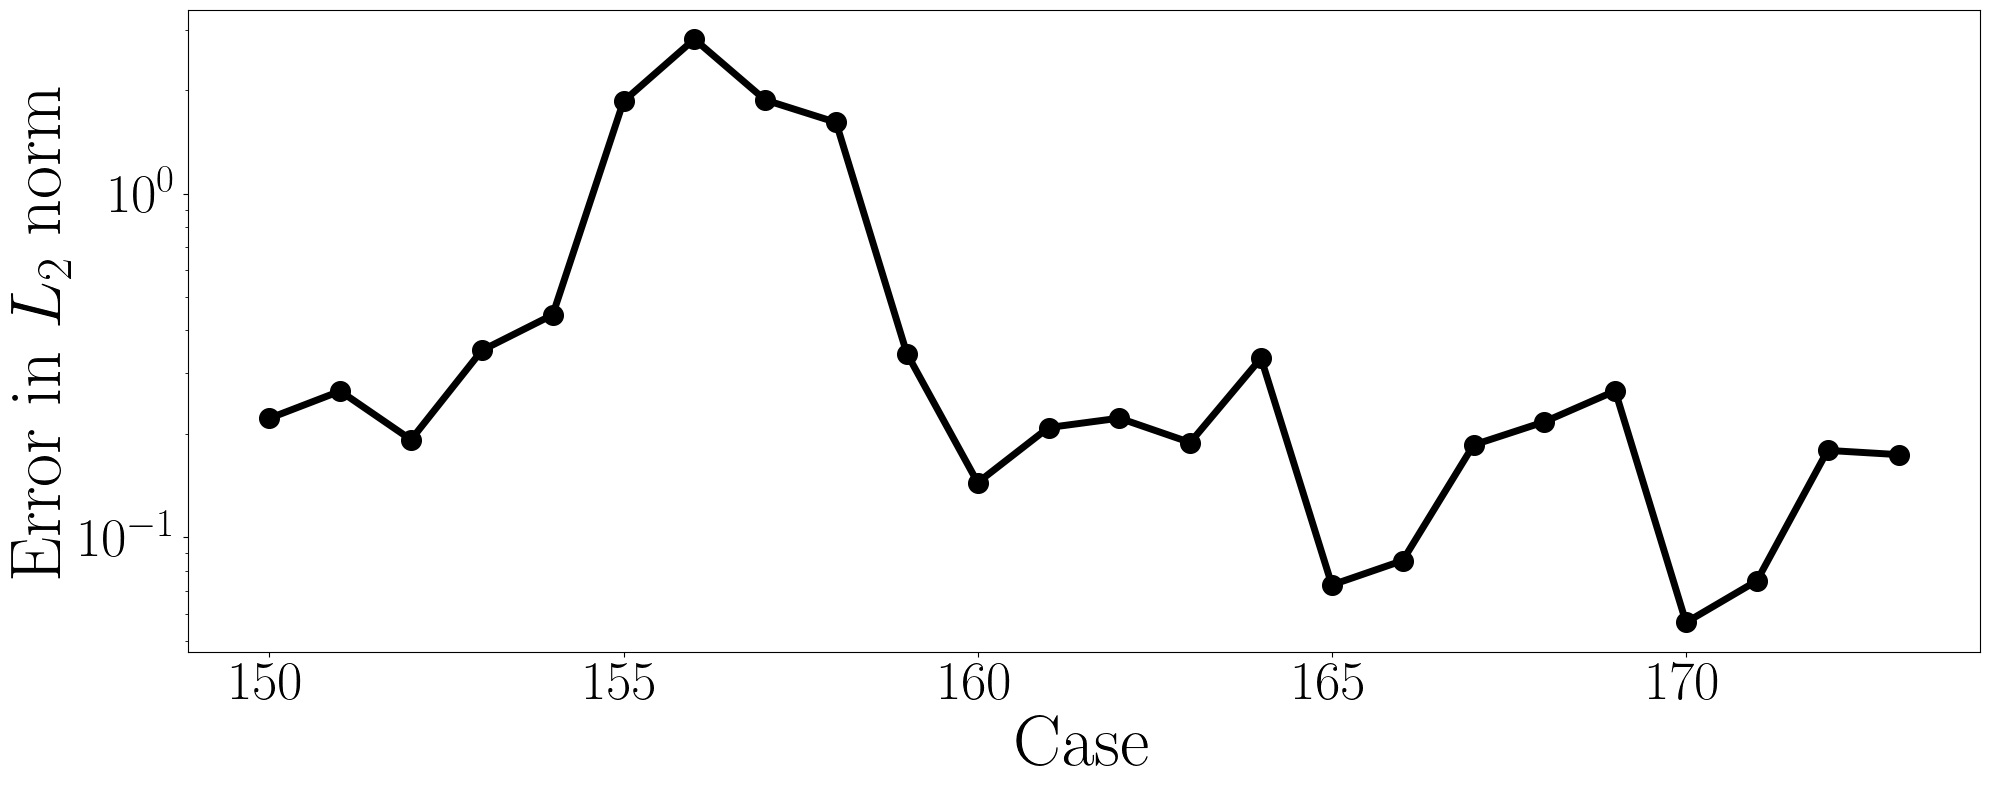

In [3]:
fig, ax = plt.subplots(figsize=(20, 8))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, errors_l2, color="black", linewidth=5)
ax.scatter(case_nums, errors_l2, color="black", s=200)

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::5])

ax.set_yscale("log")

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel("Case", fontsize=52)
ax.set_ylabel(r"Error in $L_2$ norm", fontsize=52)

plt.tight_layout()

# plt.savefig("err_tube_geo.pdf")
plt.savefig("err_tube_prop.pdf")
# plt.savefig("err_tube_bc.pdf")

In [5]:
print(f"{errors_l2.mean()} +- {errors_l2.std()}")

0.22281855801221895 +- 0.22380690469657027


In [ ]:
indexed_values = list(zip(case_nums, errors_l2))

sorted_errors = sorted(indexed_values, key=lambda item: item[1], reverse=True)

for row in sorted_errors:
    print(f"{row[0]} -> {row[1]}")

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

plt.scatter(reynolds, errors_l2, color="black")

for i, (x, y) in enumerate(zip(reynolds, errors_l2)):
    if case_nums[i] % 10 == 0:
        plt.text(x, y, str(case_nums[i]), fontsize=20, ha='right', va='bottom')

ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_xlabel("Reynolds number", fontsize=24)
ax.set_ylabel(r"Relative error in $L_2$ norm", fontsize=24)

plt.savefig("prop_reynolds.pdf")

In [ ]:
# case_path = os.path.join("./benchmark_comparison_results_new/", str(154), "err_l2.npy")
# case_path = "../../../CFDBench/tube/prop/case0065/u.npy"
case_path = os.path.join("./benchmark_comparison_results_new_new/cylinder", str(0), "err_l2.npy")
err = np.load(case_path)

fig, ax = plt.subplots(1, 2, figsize=(12, 8))

im = ax[0].imshow(err)

case_path = "../../../CFDBench/tube/prop/case0061/u.npy"
err = np.load(case_path)

ax[1].imshow(err[-1])

ax[0].axis("off")
ax[1].axis("off")

ax[0].set_title("Case 161", fontsize=24)
ax[1].set_title("Case 156", fontsize=24)

plt.colorbar(im)

plt.tight_layout()

# plt.savefig("geom_faulty.pdf")

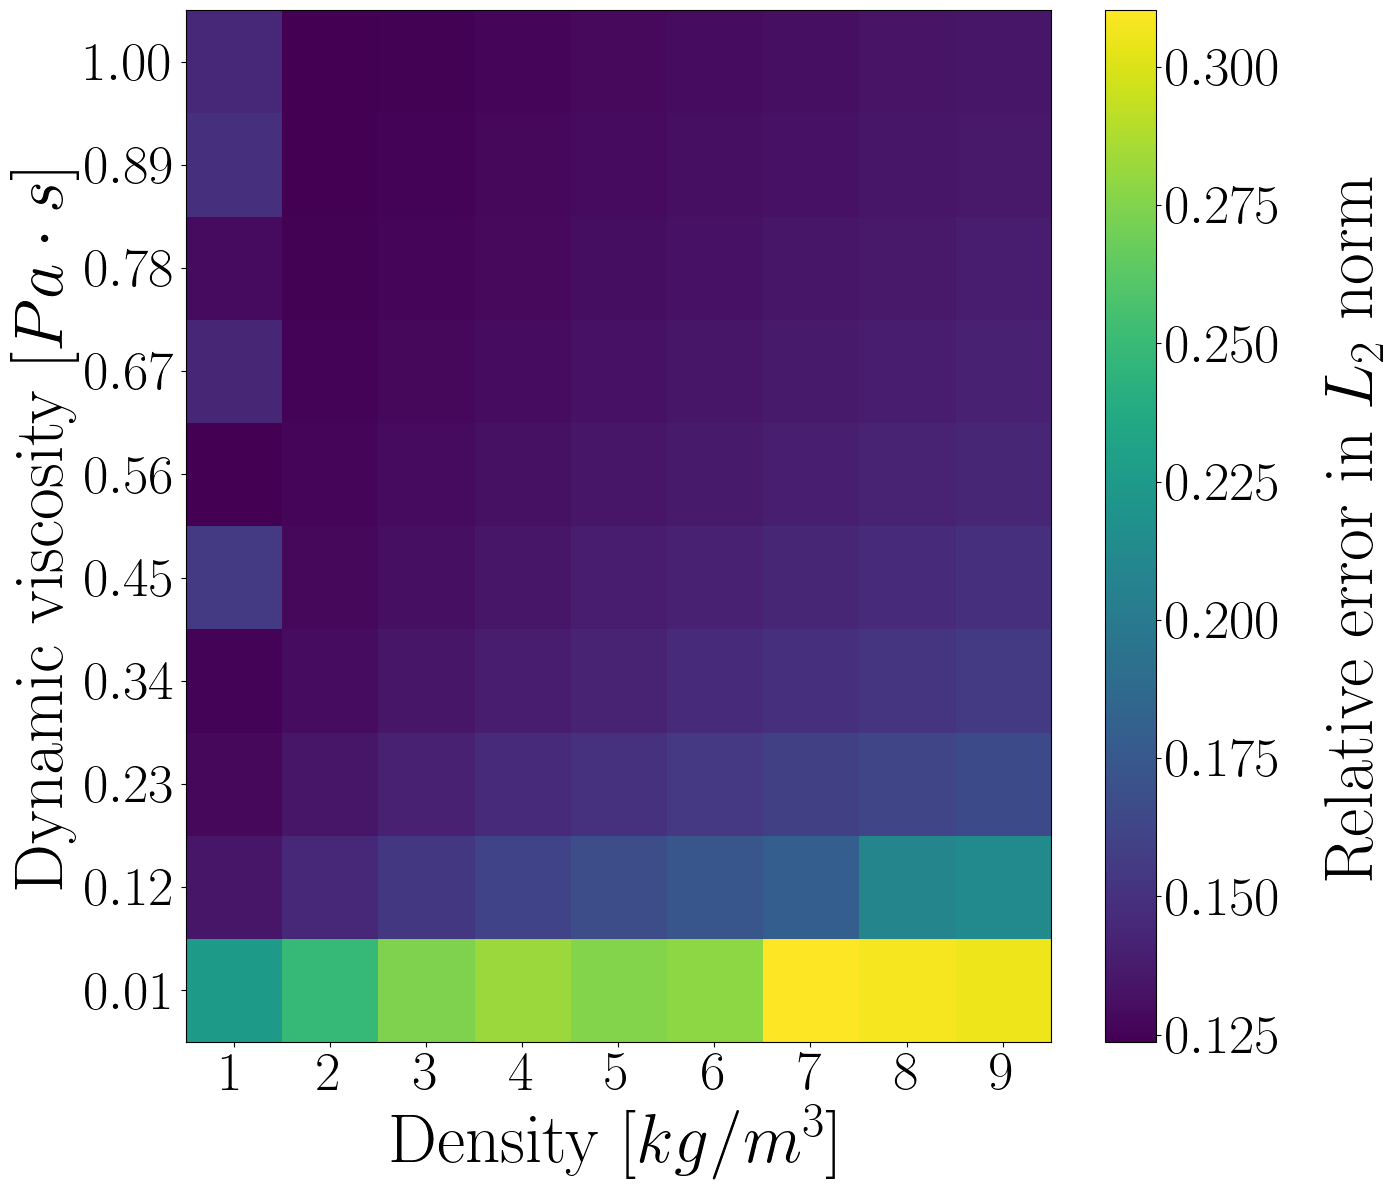

In [33]:
CFDBENCH_PATH = "../../../CFDBench/tube/prop"

grid = {}

Re = []

for fname in os.listdir(CFDBENCH_PATH):
    case_num = int(fname.split("case")[1])

    if case_num not in error_dict.keys():
        continue

    with open(os.path.join(CFDBENCH_PATH, fname, "case.json")) as f:
        case_ = json.load(f)

    d = case_["density"]
    v = case_["viscosity"]

    r = (d * case_["vel_in"] * case_["height"]) / v
    # Re[case_num] = r
    Re.append(round(r, 1))

    grid[(d, v)] = error_dict[case_num] #/ max(errors_l2)

densities = sorted(list(set(d for d, v in grid.keys())))
viscosities = sorted(list(set(v for d, v in grid.keys())))

img = np.zeros((len(viscosities), len(densities)))
for i, v in enumerate(viscosities):
    for j, d in enumerate(densities):
        img[i, j] = grid.get((d, v), np.nan)

fig, ax = plt.subplots(figsize=(14, 12))

dx = (densities[1] - densities[0]) / 2
dy = (viscosities[1] - viscosities[0]) / 2

extent = [
    min(densities) - dx,
    max(densities) + dx,
    min(viscosities) - dy,
    max(viscosities) + dy,
]

im = ax.imshow(
    img, origin="lower", extent=extent, aspect="auto", cmap="viridis"
)

cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=40)

cbar.set_label(r"Relative error in $L_2$ norm", fontsize=50, labelpad=30)

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Density $[kg/m^3]$", fontsize=50)
ax.set_ylabel(r"Dynamic viscosity $[Pa \cdot s]$", fontsize=50)

ax.set_xticks(densities)
ax.set_yticks(viscosities)

plt.tight_layout()

plt.savefig("visc_dens_map.pdf")

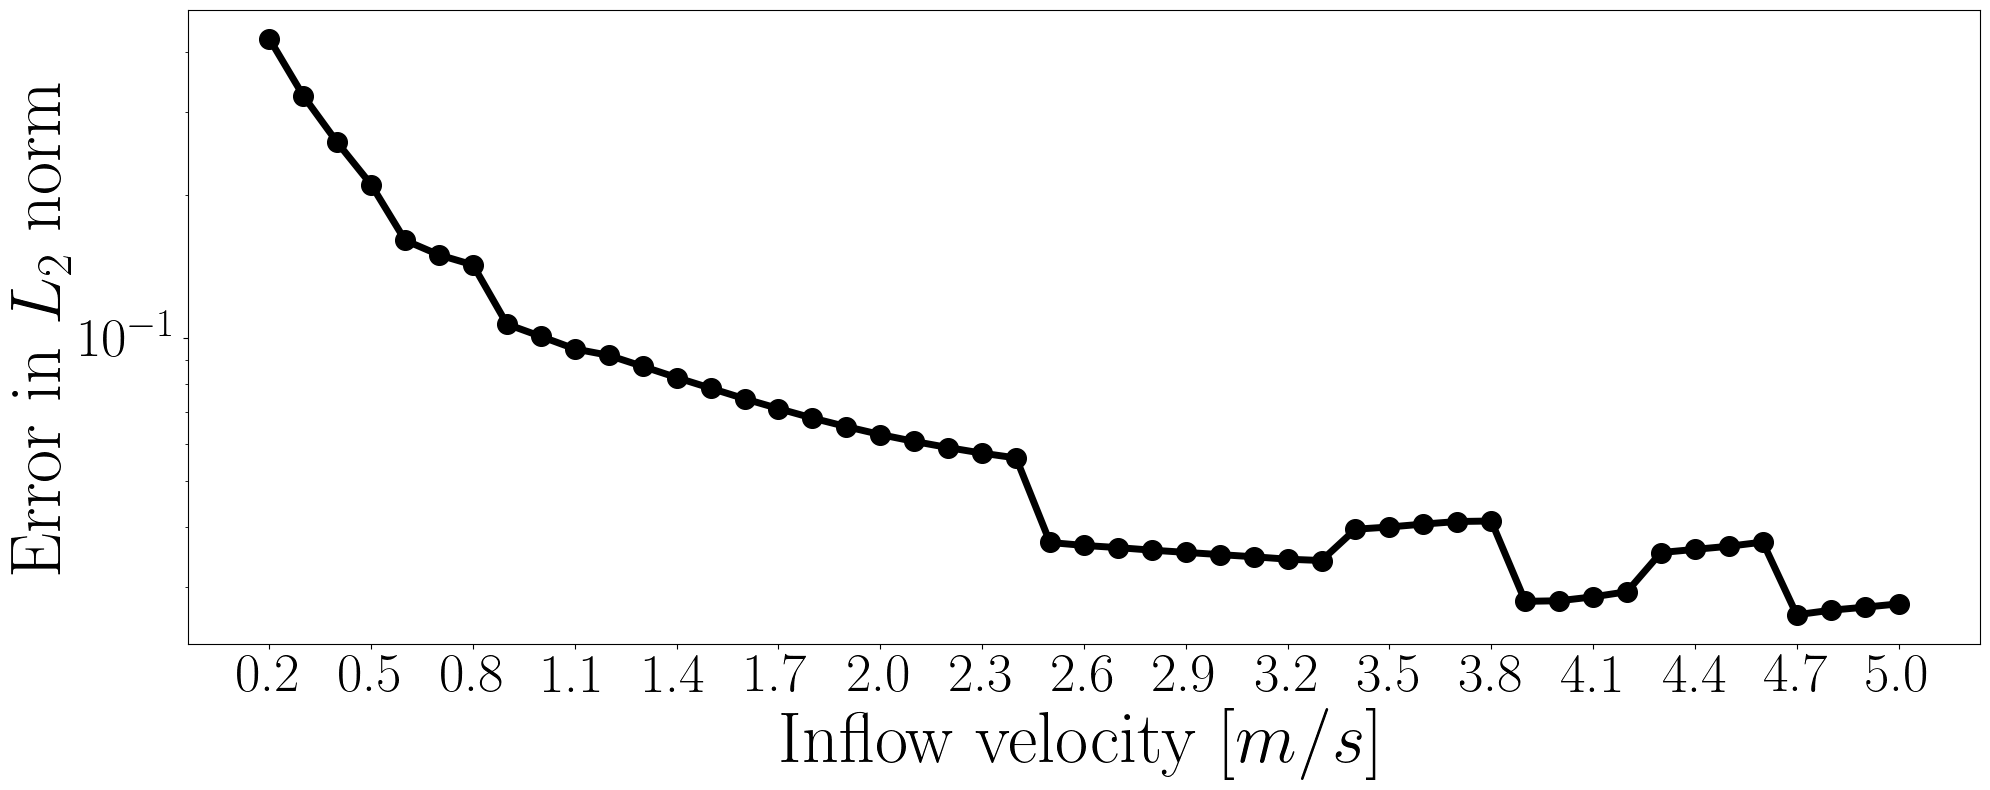

In [14]:
fig, ax = plt.subplots(figsize=(20, 8))

CFDBENCH_PATH = "../../../CFDBench/tube/bc"

vels = []

for fname in os.listdir(CFDBENCH_PATH):
    case_num = int(fname.split("case")[1])

    if case_num not in error_dict.keys():
        continue

    with open(os.path.join(CFDBENCH_PATH, fname, "case.json")) as f:
        case_ = json.load(f)

    vels.append(round(case_["vel_in"], 1))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, errors_l2, color="black", linewidth=5)
ax.scatter(case_nums, errors_l2, color="black", s=200)

# ax.plot(case_nums, abs_errors_l2, color="black", linewidth=5)
# ax.scatter(case_nums, abs_errors_l2, color="black", s=200)

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::3])

ax.set_yscale("log")

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Inflow velocity $[m/s]$", fontsize=52)
ax.set_ylabel(r"Error in $L_2$ norm", fontsize=52)

ax.set_xticklabels(vels[::3])

plt.tight_layout()

# plt.savefig("err_tube_geo.pdf")
# plt.savefig("err_tube_prop.pdf")
plt.savefig("err_tube_bc.pdf")

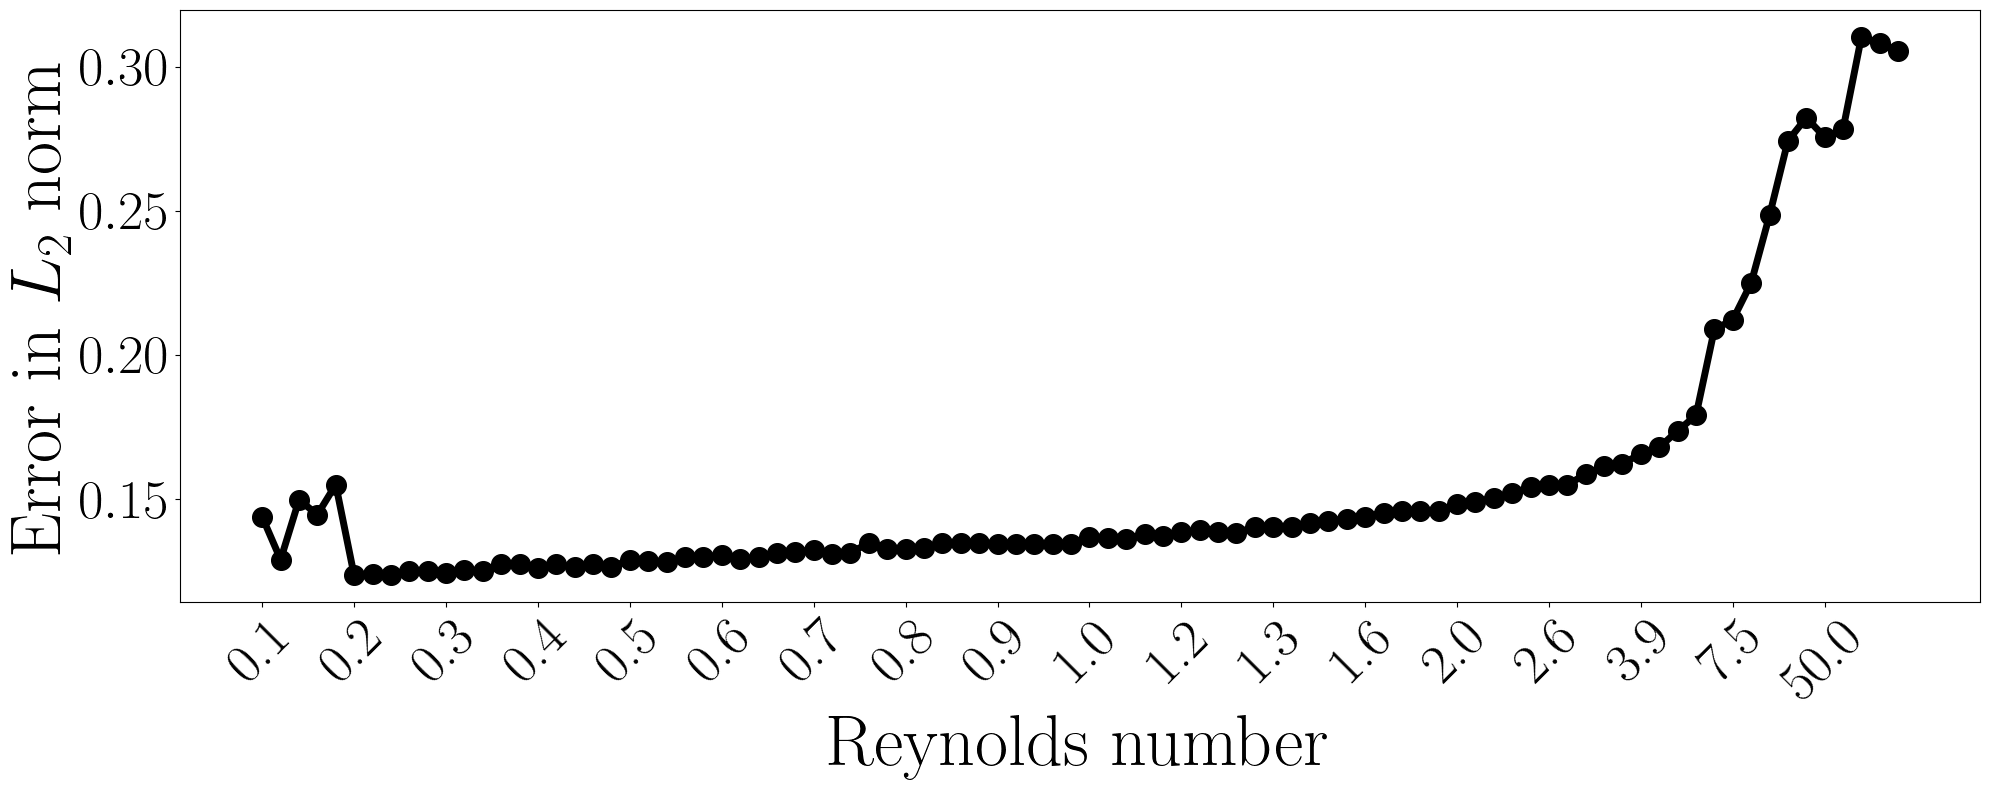

In [79]:
fig, ax = plt.subplots(figsize=(20, 8))

sorted_data = sorted(zip(Re, errors_l2), key=lambda x: x[0])
Re_sorted, errors_l2_sorted = zip(*sorted_data)

Re = list(Re_sorted)
errors_l2 = list(errors_l2_sorted)
case_nums = list(range(len(Re)))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, errors_l2, color="black", linewidth=5)
ax.scatter(case_nums, errors_l2, color="black", s=200)

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::5])

# ax.set_yscale("log")

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Reynolds number", fontsize=52)
ax.set_ylabel(r"Error in $L_2$ norm", fontsize=52)

ax.set_xticklabels(Re[::5], rotation=45)

plt.tight_layout()

# plt.savefig("err_tube_geo.pdf")
# plt.savefig("err_tube_prop.pdf")
plt.savefig("err_tube_prop.pdf")

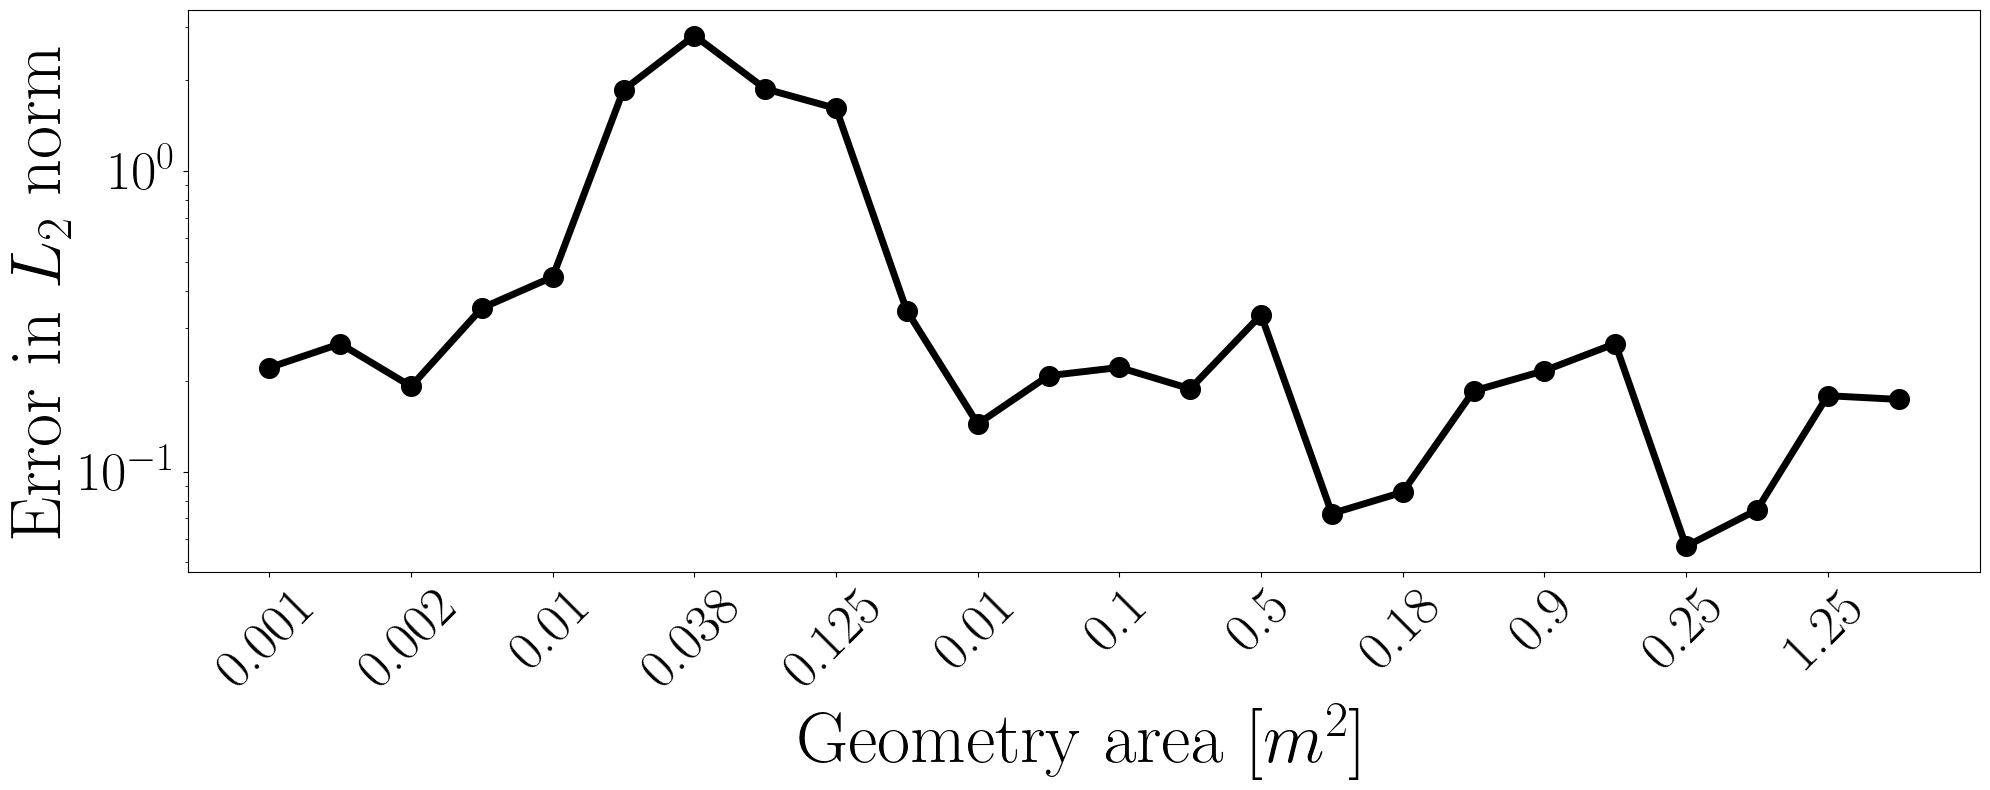

In [4]:
fig, ax = plt.subplots(figsize=(20, 8))

CFDBENCH_PATH = "../../../CFDBench/tube/geo"

heights = []
widths = []
metric = []

for fname in os.listdir(CFDBENCH_PATH):
    case_num = int(fname.split("case")[1])

    if case_num not in error_dict.keys():
        continue

    with open(os.path.join(CFDBENCH_PATH, fname, "case.json")) as f:
        case_ = json.load(f)

    heights.append(case_["height"])
    widths.append(case_["width"])

    # metric.append(fr"{round(case_["height"], 2)} $\times$ {round(case_["width"], 2)}")
    metric.append(round(case_["width"] * case_["height"], 3))
    # metric.append(round(case_["width"] ** 2 * case_["height"] ** 2, 2))


# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, errors_l2, color="black", linewidth=5)
ax.scatter(case_nums, errors_l2, color="black", s=200)

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::2])

ax.set_yscale("log")

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Geometry area [$m^2$]", fontsize=52)
ax.set_ylabel(r"Error in $L_2$ norm", fontsize=52)

ax.set_xticklabels(metric[::2], fontsize=40, rotation=45)

plt.tight_layout()

# plt.savefig("err_tube_geo.pdf")
# plt.savefig("err_tube_prop.pdf")
plt.savefig("err_tube_geo.pdf")

## Divergence

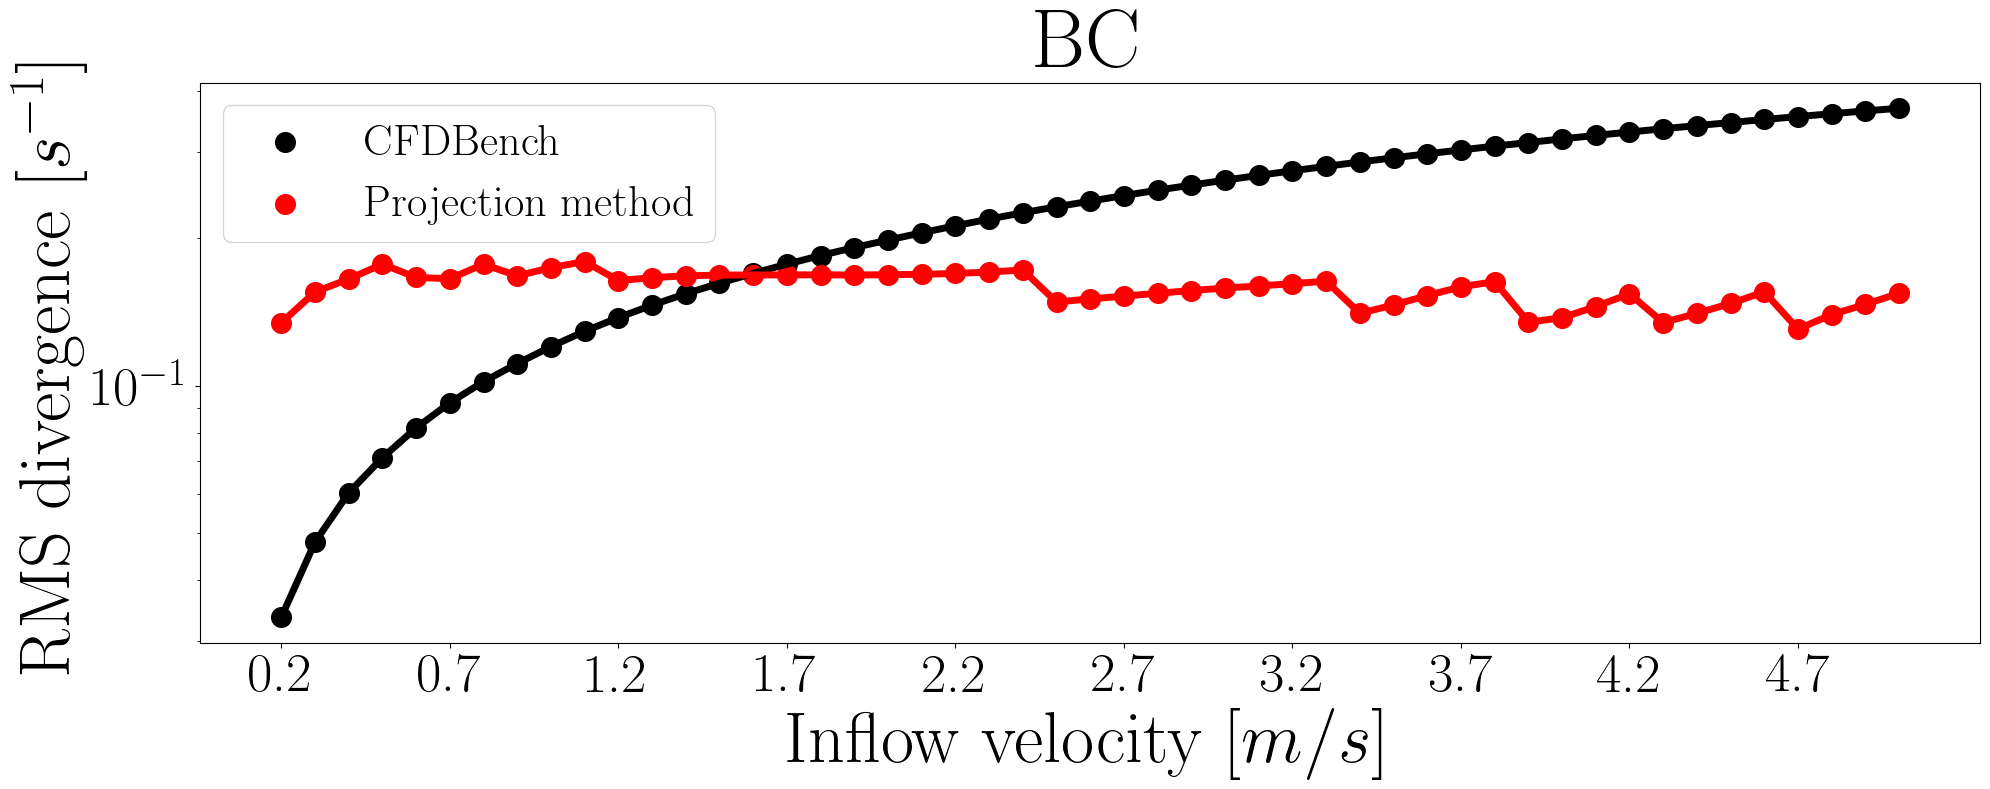

In [37]:
fig, ax = plt.subplots(figsize=(20, 8))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, err_div_baseline, color="black", linewidth=5)
ax.scatter(case_nums, err_div_baseline, color="black", s=200, label="CFDBench")

ax.plot(case_nums, err_div, color="red", linewidth=5)
ax.scatter(case_nums, err_div, color="red", s=200, label="Projection method")

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::5])
ax.set_xticklabels(vels[::5])

ax.set_yscale("log")
ax.yaxis.set_minor_formatter(NullFormatter())

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Inflow velocity $[m/s]$", fontsize=52)
ax.set_ylabel(r"RMS divergence [$s^{-1}$]", fontsize=52)


plt.legend(fontsize=32)

plt.title("BC", fontsize=60)
# plt.title("Geometry", fontsize=60)
# plt.title("Properties", fontsize=60)

plt.tight_layout()

# plt.savefig("div_err_tube_geo.pdf")
# plt.savefig("div_err_tube_prop.pdf")
plt.savefig("div_err_tube_bc.pdf")

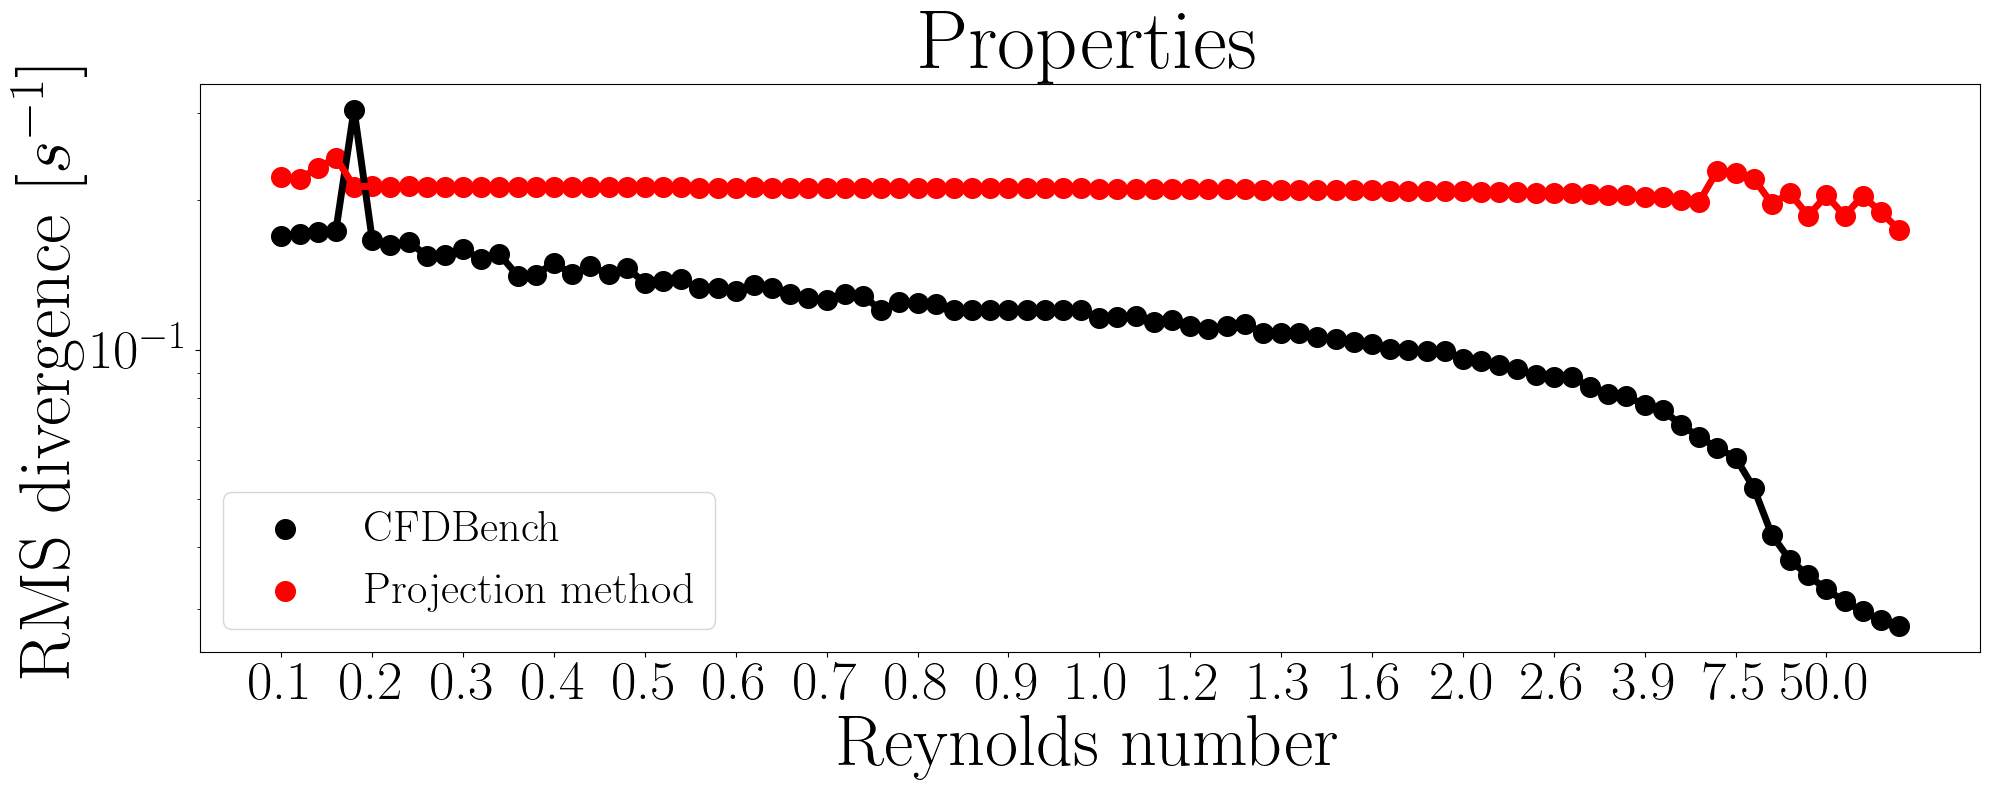

In [34]:
fig, ax = plt.subplots(figsize=(20, 8))

sorted_data = sorted(zip(Re, err_div_baseline), key=lambda x: x[0])
Re_sorted, err_div_baseline_ = zip(*sorted_data)

sorted_data = sorted(zip(Re, err_div), key=lambda x: x[0])
Re_sorted, err_div_ = zip(*sorted_data)

Re_ = list(Re_sorted)
case_nums = list(range(len(Re)))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, err_div_baseline_, color="black", linewidth=5)
ax.scatter(case_nums, err_div_baseline_, color="black", s=200, label="CFDBench")

ax.plot(case_nums, err_div_, color="red", linewidth=5)
ax.scatter(case_nums, err_div_, color="red", s=200, label="Projection method")

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::5])
ax.set_xticklabels(Re_[::5])

ax.set_yscale("log")
ax.yaxis.set_minor_formatter(NullFormatter())

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Reynolds number", fontsize=52)
ax.set_ylabel(r"RMS divergence [$s^{-1}$]", fontsize=52)


plt.legend(fontsize=32)

plt.title("Properties", fontsize=60)
# plt.title("Geometry", fontsize=60)
# plt.title("Properties", fontsize=60)

plt.tight_layout()

# plt.savefig("div_err_tube_geo.pdf")
plt.savefig("div_err_tube_prop.pdf")
# plt.savefig("div_err_tube_bc.pdf")

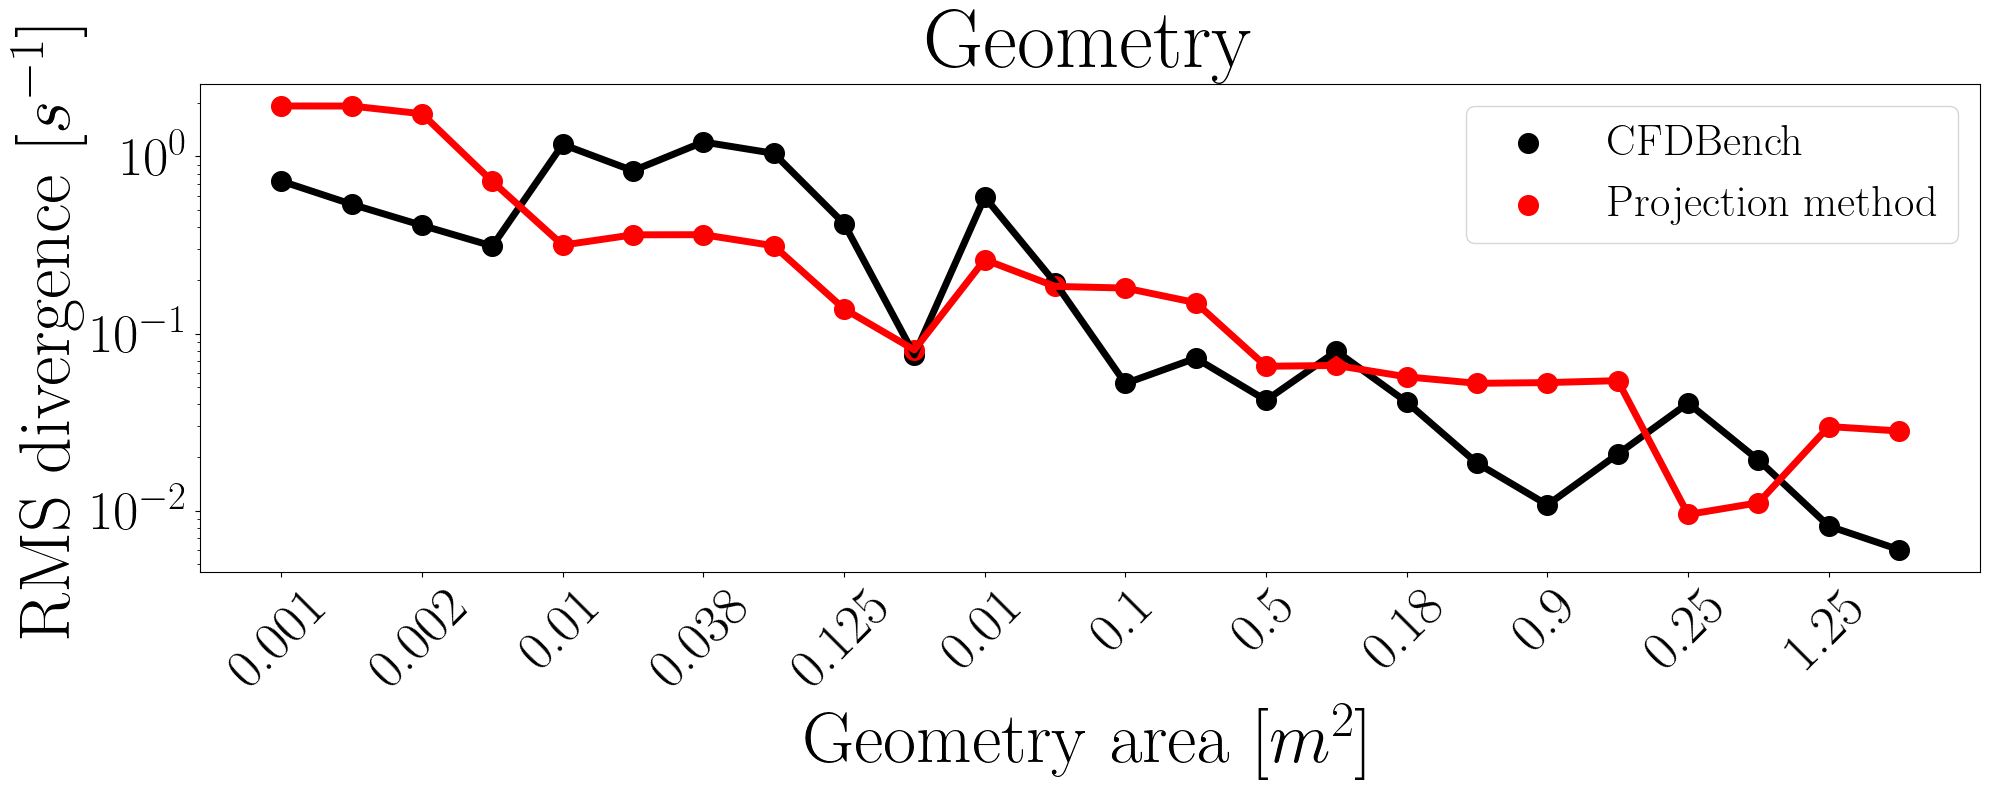

In [4]:
fig, ax = plt.subplots(figsize=(20, 8))

CFDBENCH_PATH = "../../../CFDBench/tube/geo"

heights = []
widths = []
metric = []
case_nums = []

for fname in os.listdir(CFDBENCH_PATH):
    case_num = int(fname.split("case")[1])

    if case_num not in error_dict.keys():
        continue

    case_nums.append(case_num)

    with open(os.path.join(CFDBENCH_PATH, fname, "case.json")) as f:
        case_ = json.load(f)

    heights.append(case_["height"])
    widths.append(case_["width"])

    # metric.append(fr"{round(case_["height"], 2)} $\times$ {round(case_["width"], 2)}")
    metric.append(round(case_["width"] * case_["height"], 3))
    # metric.append(round(case_["width"] ** 2 * case_["height"] ** 2, 2))

# ax.bar(case_nums, errors_l2, color="black")
ax.plot(case_nums, err_div_baseline, color="black", linewidth=5)
ax.scatter(case_nums, err_div_baseline, color="black", s=200, label="CFDBench")

ax.plot(case_nums, err_div, color="red", linewidth=5)
ax.scatter(case_nums, err_div, color="red", s=200, label="Projection method")

# for i in range(len(case_nums)):
#     if errors_l2[i] > 0.1:
#         ax.scatter(case_nums[i], errors_l2[i], color="red", s=500)
#         ax.plot((case_nums[i], case_nums[i]), (0, errors_l2[i]), color="red", linewidth=3, linestyle="-")
#     else:
#         ax.scatter(case_nums[i], errors_l2[i], color="black", s=500)

ax.set_xticks(case_nums[::2])
ax.set_xticklabels(metric[::2], rotation=45)

ax.set_yscale("log")
ax.yaxis.set_minor_formatter(NullFormatter())

ax.tick_params(axis='both', which='major', labelsize=40)
ax.set_xlabel(r"Geometry area [$m^2$]", fontsize=52)
ax.set_ylabel(r"RMS divergence [$s^{-1}$]", fontsize=52)


plt.legend(fontsize=32)

plt.title("Geometry", fontsize=60)
# plt.title("Geometry", fontsize=60)
# plt.title("Properties", fontsize=60)

plt.tight_layout()

plt.savefig("div_err_tube_geo.pdf")
# plt.savefig("div_err_tube_prop.pdf")
# plt.savefig("div_err_tube_bc.pdf")